In [1]:
# ============================================================
# CELL 1 — GOOGLE DRIVE + YOLO SETUP
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

!pip install -q ultralytics

import torch
import ultralytics

print("Python:")
!python --version

print("\nPyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("GPU is not available. Select T4 GPU in Colab.")

from ultralytics import YOLO

model = YOLO("yolov8n-pose.pt")
model.to("cuda")

print("\nYOLO device:", model.device)
print("YOLOv8 Pose ready.")

Mounted at /content/drive
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 32.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 75.8/75.8 kB 7.4 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Python:
Python 3.13.15

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4

YOLO device: cuda:0
YOLOv8 Pose ready.


In [2]:
# ============================================================
# CELL 2 — DOWNLOAD UR FALL DATASET
# ============================================================

import os
import glob
import kagglehub

print("Downloading UR Fall Detection Dataset...")

UR_ROOT = kagglehub.dataset_download(
    "sumanpunshi/ur-fall-detection-dataset/versions/1"
)

print("\nDataset downloaded to:")
print(UR_ROOT)

# Find Fall / ADL folders
fall_dir = os.path.join(
    UR_ROOT,
    "UR_data",
    "Fall"
)

adl_dir = os.path.join(
    UR_ROOT,
    "UR_data",
    "ADL"
)

print("\nFall folder exists:", os.path.exists(fall_dir))
print("ADL folder exists:", os.path.exists(adl_dir))

fall_sequences = sorted(
    [
        d for d in glob.glob(os.path.join(fall_dir, "*"))
        if os.path.isdir(d)
    ]
)

adl_sequences = sorted(
    [
        d for d in glob.glob(os.path.join(adl_dir, "*"))
        if os.path.isdir(d)
    ]
)

print("\nFall sequences:", len(fall_sequences))
print("ADL sequences:", len(adl_sequences))

if len(fall_sequences) == 30 and len(adl_sequences) == 40:
    print("\n✅ UR DATASET READY")
else:
    print("\n⚠️ Check the sequence counts.")

Using Colab cache for faster access to the 'ur-fall-detection-dataset' dataset.

Dataset downloaded to:
/kaggle/input/ur-fall-detection-dataset

Fall folder exists: True
ADL folder exists: True

Fall sequences: 30
ADL sequences: 40

✅ UR DATASET READY


In [3]:
# ============================================================
# CELL 3 — PROJECT FOLDERS
# ============================================================

PROJECT_DIR = (
    "/content/drive/MyDrive/"
    "fall_detection_project"
)

FEATURE_DIR = os.path.join(
    PROJECT_DIR,
    "extracted_features",
    "UR"
)

TEMPORAL_DIR = os.path.join(
    PROJECT_DIR,
    "temporal_data"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

os.makedirs(FEATURE_DIR, exist_ok=True)
os.makedirs(TEMPORAL_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

print("Project directory:")
print(PROJECT_DIR)

print("\nFeature directory:")
print(FEATURE_DIR)

print("\nTemporal directory:")
print(TEMPORAL_DIR)

print("\nModel directory:")
print(MODEL_DIR)

Project directory:
/content/drive/MyDrive/fall_detection_project

Feature directory:
/content/drive/MyDrive/fall_detection_project/extracted_features/UR

Temporal directory:
/content/drive/MyDrive/fall_detection_project/temporal_data

Model directory:
/content/drive/MyDrive/fall_detection_project/models


In [5]:
# ============================================================
# UR FEATURE EXTRACTION — CORRECTED PATH + CHECKPOINT SAFE
# ============================================================

import os
import glob
import cv2
import math
import numpy as np
import pandas as pd
import torch

print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# PATHS
# ============================================================

FEATURE_DIR = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "extracted_features/"
    "UR"
)

os.makedirs(FEATURE_DIR, exist_ok=True)

# These variables should already exist from Cell 2.
# If not, set them manually from your downloaded dataset.
print("Fall root:", fall_dir)
print("ADL root:", adl_dir)


# ============================================================
# FIND PNGS RECURSIVELY
# ============================================================

def find_pngs(sequence_path):

    # Recursive search fixes the nested-folder problem
    files = glob.glob(
        os.path.join(
            sequence_path,
            "**",
            "*.png"
        ),
        recursive=True
    )

    return sorted(files)


# ============================================================
# EXTRACT ONE SEQUENCE
# ============================================================

def extract_sequence(sequence_path, label):

    sequence_id = os.path.basename(
        sequence_path.rstrip("/")
    )

    image_files = find_pngs(sequence_path)

    if len(image_files) == 0:

        print(
            "❌ No PNG files found:",
            sequence_id
        )

        return None

    print(
        f"\n{sequence_id} | "
        f"Frames: {len(image_files)} | "
        f"Label: {label}"
    )

    rows = []

    for frame_number, image_path in enumerate(
        image_files,
        start=1
    ):

        frame = cv2.imread(image_path)

        if frame is None:
            continue

        results = model(
            frame,
            device=0,
            conf=0.25,
            verbose=False
        )

        row = {

            "dataset": "UR",
            "sequence_id": sequence_id,
            "frame": frame_number,

            "person_detected": 0,

            "shoulder_center_x": np.nan,
            "shoulder_center_y": np.nan,

            "hip_center_x": np.nan,
            "hip_center_y": np.nan,

            "knee_center_x": np.nan,
            "knee_center_y": np.nan,

            "ankle_center_x": np.nan,
            "ankle_center_y": np.nan,

            "torso_angle": np.nan,

            "bbox_width": np.nan,
            "bbox_height": np.nan,

            "aspect_ratio": np.nan,

            "person_confidence": np.nan,

            "label": label
        }

        # ----------------------------------------------------
        # PERSON DETECTION
        # ----------------------------------------------------

        if (
            len(results) > 0
            and results[0].keypoints is not None
            and len(results[0].keypoints.xy) > 0
        ):

            kp = (
                results[0]
                .keypoints
                .xy[0]
                .cpu()
                .numpy()
            )

            # Bounding box
            if (
                results[0].boxes is not None
                and len(results[0].boxes) > 0
            ):

                box = (
                    results[0]
                    .boxes
                    .xyxy[0]
                    .cpu()
                    .numpy()
                )

                x1, y1, x2, y2 = box

                bbox_width = x2 - x1
                bbox_height = y2 - y1

                if bbox_height > 0:
                    aspect_ratio = (
                        bbox_width /
                        bbox_height
                    )
                else:
                    aspect_ratio = np.nan

                confidence = float(
                    results[0]
                    .boxes
                    .conf[0]
                    .cpu()
                    .numpy()
                )

            else:

                bbox_width = np.nan
                bbox_height = np.nan
                aspect_ratio = np.nan
                confidence = np.nan

            # Body centers
            shoulder_x = (
                kp[5][0] +
                kp[6][0]
            ) / 2

            shoulder_y = (
                kp[5][1] +
                kp[6][1]
            ) / 2

            hip_x = (
                kp[11][0] +
                kp[12][0]
            ) / 2

            hip_y = (
                kp[11][1] +
                kp[12][1]
            ) / 2

            knee_x = (
                kp[13][0] +
                kp[14][0]
            ) / 2

            knee_y = (
                kp[13][1] +
                kp[14][1]
            ) / 2

            ankle_x = (
                kp[15][0] +
                kp[16][0]
            ) / 2

            ankle_y = (
                kp[15][1] +
                kp[16][1]
            ) / 2

            # Torso angle
            dx = shoulder_x - hip_x
            dy = shoulder_y - hip_y

            torso_angle = math.degrees(
                math.atan2(
                    abs(dx),
                    abs(dy)
                )
            )

            row.update({

                "person_detected": 1,

                "shoulder_center_x": shoulder_x,
                "shoulder_center_y": shoulder_y,

                "hip_center_x": hip_x,
                "hip_center_y": hip_y,

                "knee_center_x": knee_x,
                "knee_center_y": knee_y,

                "ankle_center_x": ankle_x,
                "ankle_center_y": ankle_y,

                "torso_angle": torso_angle,

                "bbox_width": bbox_width,
                "bbox_height": bbox_height,

                "aspect_ratio": aspect_ratio,

                "person_confidence": confidence
            })

        rows.append(row)

        if frame_number % 20 == 0:

            print(
                f"  Frame {frame_number}/{len(image_files)}",
                flush=True
            )

    # --------------------------------------------------------
    # DATAFRAME
    # --------------------------------------------------------

    df = pd.DataFrame(rows)

    # --------------------------------------------------------
    # MOTION FEATURES
    # --------------------------------------------------------

    df["hip_vertical_velocity"] = (
        df["hip_center_y"].diff()
    )

    df["hip_vertical_acceleration"] = (
        df["hip_vertical_velocity"].diff()
    )

    df["hip_horizontal_velocity"] = (
        df["hip_center_x"].diff()
    )

    dx = df["hip_center_x"].diff()
    dy = df["hip_center_y"].diff()

    df["body_center_movement"] = np.sqrt(
        dx ** 2 + dy ** 2
    )

    df["torso_angle_change"] = (
        df["torso_angle"].diff()
    )

    df["aspect_ratio_change"] = (
        df["aspect_ratio"].diff()
    )

    return df


# ============================================================
# BUILD SEQUENCE LIST
# ============================================================

fall_sequences = sorted(
    [
        d for d in glob.glob(
            os.path.join(fall_dir, "*")
        )
        if os.path.isdir(d)
    ]
)

adl_sequences = sorted(
    [
        d for d in glob.glob(
            os.path.join(adl_dir, "*")
        )
        if os.path.isdir(d)
    ]
)

all_sequences = []

for path in fall_sequences:

    all_sequences.append({
        "path": path,
        "label": 1
    })

for path in adl_sequences:

    all_sequences.append({
        "path": path,
        "label": 0
    })

all_sequences = sorted(
    all_sequences,
    key=lambda x: x["path"]
)

print("\n==========================================")
print("TOTAL SEQUENCES:", len(all_sequences))
print("==========================================")


# ============================================================
# CHECKPOINT EXTRACTION
# ============================================================

processed = 0
skipped = 0
failed = 0

for item in all_sequences:

    sequence_path = item["path"]
    label = item["label"]

    sequence_id = os.path.basename(
        sequence_path.rstrip("/")
    )

    output_file = os.path.join(
        FEATURE_DIR,
        sequence_id + "_features.csv"
    )

    # Skip completed
    if os.path.exists(output_file):

        print("SKIP:", sequence_id)

        skipped += 1

        continue

    print("\n" + "=" * 70)
    print("PROCESSING:", sequence_id)
    print(
        "CLASS:",
        "Fall" if label == 1 else "ADL"
    )
    print("=" * 70)

    try:

        df = extract_sequence(
            sequence_path,
            label
        )

        if df is None or len(df) == 0:

            failed += 1
            continue

        # SAVE IMMEDIATELY TO DRIVE
        df.to_csv(
            output_file,
            index=False
        )

        detected = int(
            df["person_detected"].sum()
        )

        print("\n✅ SAVED")
        print("File:", output_file)
        print("Frames:", len(df))
        print("Detected:", detected)
        print(
            "Missing:",
            len(df) - detected
        )

        processed += 1

    except Exception as e:

        print(
            "\n❌ ERROR:",
            sequence_id
        )

        print(e)

        failed += 1


# ============================================================
# FINAL STATUS
# ============================================================

saved_files = glob.glob(
    os.path.join(
        FEATURE_DIR,
        "*_features.csv"
    )
)

print("\n" + "=" * 70)
print("UR EXTRACTION STATUS")
print("=" * 70)

print("Processed:", processed)
print("Skipped:", skipped)
print("Failed:", failed)
print("CSV files:", len(saved_files))
print("Expected:", 70)

print("=" * 70)

CUDA: True
GPU: Tesla T4
Fall root: /kaggle/input/ur-fall-detection-dataset/UR_data/Fall
ADL root: /kaggle/input/ur-fall-detection-dataset/UR_data/ADL

TOTAL SEQUENCES: 70

PROCESSING: adl-01-cam0-rgb
CLASS: ADL

adl-01-cam0-rgb | Frames: 150 | Label: 0
  Frame 20/150
  Frame 40/150
  Frame 60/150
  Frame 80/150
  Frame 100/150
  Frame 120/150
  Frame 140/150

✅ SAVED
File: /content/drive/MyDrive/fall_detection_project/extracted_features/UR/adl-01-cam0-rgb_features.csv
Frames: 150
Detected: 145
Missing: 5

PROCESSING: adl-02-cam0-rgb
CLASS: ADL

adl-02-cam0-rgb | Frames: 180 | Label: 0
  Frame 20/180
  Frame 40/180
  Frame 60/180
  Frame 80/180
  Frame 100/180
  Frame 120/180
  Frame 140/180
  Frame 160/180
  Frame 180/180

✅ SAVED
File: /content/drive/MyDrive/fall_detection_project/extracted_features/UR/adl-02-cam0-rgb_features.csv
Frames: 180
Detected: 150
Missing: 30

PROCESSING: adl-03-cam0-rgb
CLASS: ADL

adl-03-cam0-rgb | Frames: 180 | Label: 0
  Frame 20/180
  Frame 40/180
  Fra

In [6]:
# ============================================================
# STEP 5A — COMBINE ALL UR FEATURE CSVs
# ============================================================

import os
import glob
import pandas as pd

FEATURE_DIR = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "extracted_features/"
    "UR"
)

OUTPUT_FILE = os.path.join(
    FEATURE_DIR,
    "UR_features_all.csv"
)

csv_files = sorted(
    glob.glob(
        os.path.join(
            FEATURE_DIR,
            "*_features.csv"
        )
    )
)

# Do not accidentally include the combined file itself
csv_files = [
    f for f in csv_files
    if os.path.basename(f) != "UR_features_all.csv"
]

print("=" * 70)
print("UR FEATURE CSV COMBINATION")
print("=" * 70)
print("CSV files found:", len(csv_files))

if len(csv_files) != 70:
    print("⚠️ WARNING: Expected 70 CSV files.")

all_data = []

for i, file in enumerate(csv_files, start=1):

    df = pd.read_csv(file)

    all_data.append(df)

    print(
        f"{i:02d}/70 | "
        f"{os.path.basename(file)} | "
        f"Frames: {len(df)}"
    )

# Combine
combined_df = pd.concat(
    all_data,
    ignore_index=True
)

# Save
combined_df.to_csv(
    OUTPUT_FILE,
    index=False
)

print("\n" + "=" * 70)
print("COMBINATION COMPLETE")
print("=" * 70)

print("Shape:", combined_df.shape)
print("Saved:", OUTPUT_FILE)

print("\nLabels:")
print(combined_df["label"].value_counts())

print("\nDatasets:")
print(combined_df["dataset"].value_counts())

print("\nPerson detection:")
print(combined_df["person_detected"].value_counts())

print("\nMissing values:")
print(
    combined_df.isna().sum()
)

print("=" * 70)

UR FEATURE CSV COMBINATION
CSV files found: 70
01/70 | adl-01-cam0-rgb_features.csv | Frames: 150
02/70 | adl-02-cam0-rgb_features.csv | Frames: 180
03/70 | adl-03-cam0-rgb_features.csv | Frames: 180
04/70 | adl-04-cam0-rgb_features.csv | Frames: 150
05/70 | adl-05-cam0-rgb_features.csv | Frames: 180
06/70 | adl-06-cam0-rgb_features.csv | Frames: 230
07/70 | adl-07-cam0-rgb_features.csv | Frames: 180
08/70 | adl-08-cam0-rgb_features.csv | Frames: 180
09/70 | adl-09-cam0-rgb_features.csv | Frames: 150
10/70 | adl-10-cam0-rgb_features.csv | Frames: 300
11/70 | adl-11-cam0-rgb_features.csv | Frames: 300
12/70 | adl-12-cam0-rgb_features.csv | Frames: 250
13/70 | adl-13-cam0-rgb_features.csv | Frames: 265
14/70 | adl-14-cam0-rgb_features.csv | Frames: 235
15/70 | adl-15-cam0-rgb_features.csv | Frames: 275
16/70 | adl-16-cam0-rgb_features.csv | Frames: 240
17/70 | adl-17-cam0-rgb_features.csv | Frames: 230
18/70 | adl-18-cam0-rgb_features.csv | Frames: 265
19/70 | adl-19-cam0-rgb_features.cs

In [7]:
# ============================================================
# STEP 5B — CLEAN + SPLIT + CREATE TEMPORAL SEQUENCES
# ============================================================

import os
import random
import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import joblib

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

INPUT_FILE = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "extracted_features/"
    "UR/"
    "UR_features_all.csv"
)

OUTPUT_DIR = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "temporal_dataset/"
    "UR"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# SETTINGS
# ------------------------------------------------------------

WINDOW_SIZE = 60       # ~2 seconds at 30 FPS
STRIDE = 15            # overlapping windows
MIN_DETECTION_RATE = 0.70

RANDOM_STATE = 42

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

print("=" * 70)
print("LOADED UR DATASET")
print("=" * 70)

print("Total frames:", len(df))
print("Sequences:", df["sequence_id"].nunique())

# ------------------------------------------------------------
# FEATURES
# ------------------------------------------------------------

FEATURE_COLUMNS = [
    "shoulder_center_x",
    "shoulder_center_y",
    "hip_center_x",
    "hip_center_y",
    "knee_center_x",
    "knee_center_y",
    "ankle_center_x",
    "ankle_center_y",
    "torso_angle",
    "bbox_width",
    "bbox_height",
    "aspect_ratio",
    "person_confidence",
    "hip_vertical_velocity",
    "hip_vertical_acceleration",
    "hip_horizontal_velocity",
    "body_center_movement",
    "torso_angle_change",
    "aspect_ratio_change"
]

print("\nFeatures:", len(FEATURE_COLUMNS))

# ------------------------------------------------------------
# CHECK DETECTION RATE PER SEQUENCE
# ------------------------------------------------------------

sequence_stats = (
    df.groupby(["sequence_id", "label"])
      .agg(
          total_frames=("frame", "count"),
          detected_frames=("person_detected", "sum")
      )
      .reset_index()
)

sequence_stats["detection_rate"] = (
    sequence_stats["detected_frames"]
    / sequence_stats["total_frames"]
)

print("\nDetection-rate statistics:")
print(
    sequence_stats["detection_rate"].describe()
)

# ------------------------------------------------------------
# REMOVE ONLY VERY POORLY DETECTED SEQUENCES
# ------------------------------------------------------------

valid_sequences = sequence_stats[
    sequence_stats["detection_rate"] >= MIN_DETECTION_RATE
]["sequence_id"].tolist()

removed_sequences = sequence_stats[
    sequence_stats["detection_rate"] < MIN_DETECTION_RATE
]

print("\n" + "=" * 70)
print("SEQUENCE QUALITY CHECK")
print("=" * 70)

print(
    "Valid sequences:",
    len(valid_sequences)
)

print(
    "Removed sequences:",
    len(removed_sequences)
)

if len(removed_sequences) > 0:
    print("\nRemoved:")
    print(
        removed_sequences[
            [
                "sequence_id",
                "label",
                "total_frames",
                "detected_frames",
                "detection_rate"
            ]
        ].to_string(index=False)
    )

df = df[
    df["sequence_id"].isin(valid_sequences)
].copy()

# ------------------------------------------------------------
# TRAIN / VALIDATION / TEST SPLIT BY SEQUENCE
# ------------------------------------------------------------

sequence_info = (
    df[
        ["sequence_id", "label"]
    ]
    .drop_duplicates()
)

fall_sequences = sequence_info[
    sequence_info["label"] == 1
]["sequence_id"].tolist()

adl_sequences = sequence_info[
    sequence_info["label"] == 0
]["sequence_id"].tolist()

print("\nRemaining Fall sequences:", len(fall_sequences))
print("Remaining ADL sequences:", len(adl_sequences))

# 70% train, 15% validation, 15% test
fall_train, fall_temp = train_test_split(
    fall_sequences,
    test_size=0.30,
    random_state=RANDOM_STATE
)

fall_val, fall_test = train_test_split(
    fall_temp,
    test_size=0.50,
    random_state=RANDOM_STATE
)

adl_train, adl_temp = train_test_split(
    adl_sequences,
    test_size=0.30,
    random_state=RANDOM_STATE
)

adl_val, adl_test = train_test_split(
    adl_temp,
    test_size=0.50,
    random_state=RANDOM_STATE
)

train_sequences = fall_train + adl_train
val_sequences = fall_val + adl_val
test_sequences = fall_test + adl_test

random.seed(RANDOM_STATE)

random.shuffle(train_sequences)
random.shuffle(val_sequences)
random.shuffle(test_sequences)

print("\n" + "=" * 70)
print("SEQUENCE SPLIT")
print("=" * 70)

print(
    "Train:",
    len(train_sequences),
    "| Fall:",
    len(fall_train),
    "| ADL:",
    len(adl_train)
)

print(
    "Validation:",
    len(val_sequences),
    "| Fall:",
    len(fall_val),
    "| ADL:",
    len(adl_val)
)

print(
    "Test:",
    len(test_sequences),
    "| Fall:",
    len(fall_test),
    "| ADL:",
    len(adl_test)
)

# ------------------------------------------------------------
# HANDLE MISSING VALUES
# ------------------------------------------------------------
#
# Important:
# We do NOT replace missing detections with 0.
#
# Instead:
# 1. interpolate short gaps within each sequence
# 2. forward/backward fill remaining edge gaps
# 3. retain detection indicator as information
#
# ------------------------------------------------------------

df["person_detected"] = df["person_detected"].astype(float)

for col in FEATURE_COLUMNS:

    df[col] = (
        df.groupby("sequence_id")[col]
          .transform(
              lambda x:
              x.interpolate(
                  method="linear",
                  limit_direction="both"
              )
          )
    )

# Any extremely rare remaining NaN
# is replaced by the training-set median later.

# ------------------------------------------------------------
# ADD DETECTION INDICATOR AS A FEATURE
# ------------------------------------------------------------

MODEL_FEATURES = FEATURE_COLUMNS + [
    "person_detected"
]

print(
    "\nFinal model feature count:",
    len(MODEL_FEATURES)
)

# ------------------------------------------------------------
# FIT SCALER ONLY ON TRAINING FRAMES
# ------------------------------------------------------------

train_df = df[
    df["sequence_id"].isin(train_sequences)
].copy()

# Calculate medians only from training data
train_medians = train_df[
    MODEL_FEATURES
].median()

train_df[MODEL_FEATURES] = (
    train_df[MODEL_FEATURES]
    .fillna(train_medians)
)

scaler = StandardScaler()

scaler.fit(
    train_df[MODEL_FEATURES]
)

# ------------------------------------------------------------
# FUNCTION TO CREATE TEMPORAL WINDOWS
# ------------------------------------------------------------

def create_sequences(
    data,
    sequence_ids,
    scaler,
    medians,
    window_size=60,
    stride=15
):

    X = []
    y = []
    window_sequence_ids = []

    for sequence_id in sequence_ids:

        seq = data[
            data["sequence_id"] == sequence_id
        ].sort_values("frame").copy()

        if len(seq) < window_size:
            continue

        features = (
            seq[MODEL_FEATURES]
            .fillna(medians)
            .values
        )

        features = scaler.transform(
            features
        )

        label = int(
            seq["label"].iloc[0]
        )

        # Sliding windows
        for start in range(
            0,
            len(features) - window_size + 1,
            stride
        ):

            end = start + window_size

            window = features[
                start:end
            ]

            X.append(window)
            y.append(label)
            window_sequence_ids.append(
                sequence_id
            )

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int64),
        window_sequence_ids
    )

# ------------------------------------------------------------
# CREATE TRAIN / VALIDATION / TEST SEQUENCES
# ------------------------------------------------------------

X_train, y_train, train_ids = create_sequences(
    df,
    train_sequences,
    scaler,
    train_medians,
    WINDOW_SIZE,
    STRIDE
)

X_val, y_val, val_ids = create_sequences(
    df,
    val_sequences,
    scaler,
    train_medians,
    WINDOW_SIZE,
    STRIDE
)

X_test, y_test, test_ids = create_sequences(
    df,
    test_sequences,
    scaler,
    train_medians,
    WINDOW_SIZE,
    STRIDE
)

# ------------------------------------------------------------
# RESULTS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEMPORAL DATASET CREATED")
print("=" * 70)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining labels:")
print(
    pd.Series(y_train).value_counts().sort_index()
)

print("\nValidation labels:")
print(
    pd.Series(y_val).value_counts().sort_index()
)

print("\nTest labels:")
print(
    pd.Series(y_test).value_counts().sort_index()
)

# ------------------------------------------------------------
# SAVE TEMPORAL DATASET
# ------------------------------------------------------------

np.save(
    os.path.join(OUTPUT_DIR, "X_train.npy"),
    X_train
)

np.save(
    os.path.join(OUTPUT_DIR, "y_train.npy"),
    y_train
)

np.save(
    os.path.join(OUTPUT_DIR, "X_val.npy"),
    X_val
)

np.save(
    os.path.join(OUTPUT_DIR, "y_val.npy"),
    y_val
)

np.save(
    os.path.join(OUTPUT_DIR, "X_test.npy"),
    X_test
)

np.save(
    os.path.join(OUTPUT_DIR, "y_test.npy"),
    y_test
)

joblib.dump(
    scaler,
    os.path.join(
        OUTPUT_DIR,
        "scaler.pkl"
    )
)

joblib.dump(
    train_medians,
    os.path.join(
        OUTPUT_DIR,
        "train_medians.pkl"
    )
)

# Save split information
split_info = {
    "train_sequences": train_sequences,
    "val_sequences": val_sequences,
    "test_sequences": test_sequences,
    "window_size": WINDOW_SIZE,
    "stride": STRIDE,
    "features": MODEL_FEATURES
}

joblib.dump(
    split_info,
    os.path.join(
        OUTPUT_DIR,
        "split_info.pkl"
    )
)

print("\n" + "=" * 70)
print("SAVED TEMPORAL DATASET")
print("=" * 70)

print("Directory:")
print(OUTPUT_DIR)

print("\nFiles:")
for file in sorted(
    os.listdir(OUTPUT_DIR)
):
    print(" ", file)

print("\n✅ STEP 5B COMPLETE")

LOADED UR DATASET
Total frames: 11936
Sequences: 70

Features: 19

Detection-rate statistics:
count    70.000000
mean      0.903424
std       0.110545
min       0.560000
25%       0.850000
50%       0.944837
75%       1.000000
max       1.000000
Name: detection_rate, dtype: float64

SEQUENCE QUALITY CHECK
Valid sequences: 65
Removed sequences: 5

Removed:
    sequence_id  label  total_frames  detected_frames  detection_rate
adl-22-cam0-rgb      0           240              156        0.650000
adl-23-cam0-rgb      0           220              149        0.677273
adl-30-cam0-rgb      0           400              224        0.560000
adl-38-cam0-rgb      0           345              219        0.634783
adl-40-cam0-rgb      0           330              226        0.684848

Remaining Fall sequences: 30
Remaining ADL sequences: 35

SEQUENCE SPLIT
Train: 45 | Fall: 21 | ADL: 24
Validation: 9 | Fall: 4 | ADL: 5
Test: 11 | Fall: 5 | ADL: 6

Final model feature count: 20


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut


TEMPORAL DATASET CREATED
X_train: (341, 60, 20)
y_train: (341,)
X_val: (64, 60, 20)
y_val: (64,)
X_test: (69, 60, 20)
y_test: (69,)

Training labels:
0    268
1     73
Name: count, dtype: int64

Validation labels:
0    50
1    14
Name: count, dtype: int64

Test labels:
0    59
1    10
Name: count, dtype: int64

SAVED TEMPORAL DATASET
Directory:
/content/drive/MyDrive/fall_detection_project/temporal_dataset/UR

Files:
  X_test.npy
  X_train.npy
  X_val.npy
  scaler.pkl
  split_info.pkl
  train_medians.pkl
  y_test.npy
  y_train.npy
  y_val.npy

✅ STEP 5B COMPLETE


In [8]:
# ============================================================
# STEP 6 — TRAIN TEMPORAL FALL DETECTION MODEL
# ============================================================

import os
import numpy as np
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    GRU,
    Dense,
    Dropout,
    BatchNormalization
)
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)
from sklearn.utils.class_weight import compute_class_weight

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

DATA_DIR = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "temporal_dataset/"
    "UR"
)

MODEL_DIR = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "models"
)

os.makedirs(MODEL_DIR, exist_ok=True)

# ------------------------------------------------------------
# LOAD DATA
# ------------------------------------------------------------

X_train = np.load(
    os.path.join(DATA_DIR, "X_train.npy")
)

y_train = np.load(
    os.path.join(DATA_DIR, "y_train.npy")
)

X_val = np.load(
    os.path.join(DATA_DIR, "X_val.npy")
)

y_val = np.load(
    os.path.join(DATA_DIR, "y_val.npy")
)

X_test = np.load(
    os.path.join(DATA_DIR, "X_test.npy")
)

y_test = np.load(
    os.path.join(DATA_DIR, "y_test.npy")
)

print("=" * 70)
print("TEMPORAL DATA LOADED")
print("=" * 70)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_val:", X_val.shape)
print("y_val:", y_val.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

# ------------------------------------------------------------
# GPU CHECK
# ------------------------------------------------------------

print("\nGPU:")
print(tf.config.list_physical_devices("GPU"))

# ------------------------------------------------------------
# CLASS WEIGHTS
# ------------------------------------------------------------

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {
    int(c): float(w)
    for c, w in zip(classes, weights)
}

print("\nClass weights:")
print(class_weights)

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

model = Sequential([
    Input(
        shape=(
            X_train.shape[1],
            X_train.shape[2]
        )
    ),

    GRU(
        64,
        return_sequences=True
    ),

    Dropout(0.30),

    GRU(
        32,
        return_sequences=False
    ),

    Dropout(0.30),

    Dense(
        32,
        activation="relu"
    ),

    BatchNormalization(),

    Dropout(0.20),

    Dense(
        1,
        activation="sigmoid"
    )
])

# ------------------------------------------------------------
# COMPILE
# ------------------------------------------------------------

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(
            name="precision"
        ),
        tf.keras.metrics.Recall(
            name="recall"
        )
    ]
)

model.summary()

# ------------------------------------------------------------
# CALLBACKS
# ------------------------------------------------------------

MODEL_PATH = os.path.join(
    MODEL_DIR,
    "ur_gru_fall_detector.keras"
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=4,
        min_lr=1e-6,
        verbose=1
    ),

    ModelCheckpoint(
        MODEL_PATH,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("STARTING TRAINING")
print("=" * 70)

history = model.fit(
    X_train,
    y_train,

    validation_data=(
        X_val,
        y_val
    ),

    epochs=50,

    batch_size=16,

    class_weight=class_weights,

    callbacks=callbacks,

    verbose=1
)

# ------------------------------------------------------------
# FINAL TEST EVALUATION
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("TEST EVALUATION")
print("=" * 70)

test_results = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

for name, value in zip(
    model.metrics_names,
    test_results
):
    print(
        f"{name}: {value:.4f}"
    )

print("\n" + "=" * 70)
print("MODEL SAVED")
print("=" * 70)

print(MODEL_PATH)

TEMPORAL DATA LOADED
X_train: (341, 60, 20)
y_train: (341,)
X_val: (64, 60, 20)
y_val: (64,)
X_test: (69, 60, 20)
y_test: (69,)

GPU:
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

Class weights:
{0: 0.6361940298507462, 1: 2.335616438356164}


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 60, 64)         │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,137 (106.00 KB)

 Trainable params: 27,073 (105.75 KB)

 Non-trainable params: 64 (256.00 B)


STARTING TRAINING
Epoch 1/50
20/22 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4872 - loss: 0.8991 - precision: 0.1727 - recall: 0.4444
Epoch 1: val_loss improved from None to 0.53660, saving model to /content/drive/MyDrive/fall_detection_project/models/ur_gru_fall_detector.keras

Epoch 1: finished saving model to /content/drive/MyDrive/fall_detection_project/models/ur_gru_fall_detector.keras
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 45ms/step - accuracy: 0.5718 - loss: 0.7257 - precision: 0.2865 - recall: 0.6712 - val_accuracy: 0.8906 - val_loss: 0.5366 - val_precision: 1.0000 - val_recall: 0.5000 - learning_rate: 0.0010
Epoch 2/50
21/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.6628 - loss: 0.5681 - precision: 0.3884 - recall: 0.8104
Epoch 2: val_loss improved from 0.53660 to 0.50937, saving model to /content/drive/MyDrive/fall_detection_project/models/ur_gru_fall_detector.keras

Epoch 2: finished saving model to /content/drive/MyDrive/fall_detection_project/models/ur_gru_fall_detecto

MODEL EVALUATION
Test samples: 69
Test shape: (69, 60, 20)

CONFUSION MATRIX

                  Predicted
                 ADL   FALL
Actual ADL        56     3
Actual FALL       1     9

FINAL METRICS
Accuracy  : 0.9420 (94.20%)
Precision : 0.7500 (75.00%)
Recall    : 0.9000 (90.00%)
F1 Score  : 0.8182 (81.82%)

True Negatives : 56
False Positives: 3
False Negatives: 1
True Positives : 9

CLASSIFICATION REPORT
                precision    recall  f1-score   support

ADL / Non-Fall     0.9825    0.9492    0.9655        59
          Fall     0.7500    0.9000    0.8182        10

      accuracy                         0.9420        69
     macro avg     0.8662    0.9246    0.8918        69
  weighted avg     0.9488    0.9420    0.9442        69



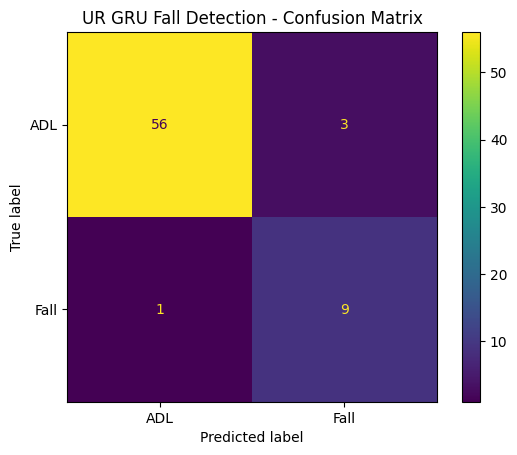


INDIVIDUAL TEST PREDICTIONS
01 | Actual: Fall | Predicted: Fall | Fall probability: 0.9682
02 | Actual: Fall | Predicted: Fall | Fall probability: 0.9995
03 | Actual: Fall | Predicted: Fall | Fall probability: 0.9981
04 | Actual: Fall | Predicted: Fall | Fall probability: 0.9991
05 | Actual: Fall | Predicted: Fall | Fall probability: 0.9984
06 | Actual: Fall | Predicted: Fall | Fall probability: 0.6334
07 | Actual: Fall | Predicted: Fall | Fall probability: 0.9764
08 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0154
09 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0229
10 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0301
11 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0346
12 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0392
13 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0660
14 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0771
15 | Actual: ADL  | Predicted: ADL  | Fall probability: 0.0757
16 | Actual: ADL  | Predic

In [9]:
# ============================================================
# STEP 7 — COMPLETE GRU MODEL EVALUATION
# ============================================================

import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

DATA_DIR = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "temporal_dataset/"
    "UR"
)

MODEL_PATH = (
    "/content/drive/MyDrive/"
    "fall_detection_project/"
    "models/"
    "ur_gru_fall_detector.keras"
)

# ------------------------------------------------------------
# LOAD TEST DATA
# ------------------------------------------------------------

X_test = np.load(
    os.path.join(
        DATA_DIR,
        "X_test.npy"
    )
)

y_test = np.load(
    os.path.join(
        DATA_DIR,
        "y_test.npy"
    )
)

# ------------------------------------------------------------
# LOAD MODEL
# ------------------------------------------------------------

model = tf.keras.models.load_model(
    MODEL_PATH
)

print("=" * 70)
print("MODEL EVALUATION")
print("=" * 70)

print("Test samples:", len(X_test))
print("Test shape:", X_test.shape)

# ------------------------------------------------------------
# PREDICTIONS
# ------------------------------------------------------------

probabilities = model.predict(
    X_test,
    verbose=0
).ravel()

# Standard threshold
THRESHOLD = 0.50

y_pred = (
    probabilities >= THRESHOLD
).astype(int)

# ------------------------------------------------------------
# METRICS
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

# ------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(
    y_test,
    y_pred
)

tn, fp, fn, tp = cm.ravel()

print("\n" + "=" * 70)
print("CONFUSION MATRIX")
print("=" * 70)

print("""
                  Predicted
                 ADL   FALL
Actual ADL        {}     {}
Actual FALL       {}     {}
""".format(
    tn,
    fp,
    fn,
    tp
))

# ------------------------------------------------------------
# PRINT METRICS
# ------------------------------------------------------------

print("=" * 70)
print("FINAL METRICS")
print("=" * 70)

print(
    f"Accuracy  : {accuracy:.4f} "
    f"({accuracy * 100:.2f}%)"
)

print(
    f"Precision : {precision:.4f} "
    f"({precision * 100:.2f}%)"
)

print(
    f"Recall    : {recall:.4f} "
    f"({recall * 100:.2f}%)"
)

print(
    f"F1 Score  : {f1:.4f} "
    f"({f1 * 100:.2f}%)"
)

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

# ------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "ADL / Non-Fall",
            "Fall"
        ],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# PLOT CONFUSION MATRIX
# ------------------------------------------------------------

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "ADL",
        "Fall"
    ]
)

disp.plot()

plt.title(
    "UR GRU Fall Detection - Confusion Matrix"
)

plt.show()

# ------------------------------------------------------------
# SHOW INDIVIDUAL PREDICTIONS
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("INDIVIDUAL TEST PREDICTIONS")
print("=" * 70)

for i in range(len(y_test)):

    actual = (
        "Fall"
        if y_test[i] == 1
        else "ADL"
    )

    predicted = (
        "Fall"
        if y_pred[i] == 1
        else "ADL"
    )

    print(
        f"{i+1:02d} | "
        f"Actual: {actual:4s} | "
        f"Predicted: {predicted:4s} | "
        f"Fall probability: "
        f"{probabilities[i]:.4f}"
    )

# ------------------------------------------------------------
# SAVE PREDICTIONS
# ------------------------------------------------------------

prediction_file = os.path.join(
    DATA_DIR,
    "test_predictions.csv"
)

import pandas as pd

prediction_df = pd.DataFrame({
    "actual": y_test,
    "predicted": y_pred,
    "fall_probability": probabilities
})

prediction_df.to_csv(
    prediction_file,
    index=False
)

print("\n" + "=" * 70)
print("EVALUATION COMPLETE")
print("=" * 70)

print(
    "Predictions saved:",
    prediction_file
)

In [10]:
# ================================================================
# STEP 8 — VALIDATION THRESHOLD ANALYSIS
# ================================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("VALIDATION THRESHOLD ANALYSIS")
print("=" * 70)

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/fall_detection_project"

TEMPORAL_DIR = os.path.join(
    BASE_DIR,
    "temporal_dataset",
    "UR"
)

MODEL_PATH = os.path.join(
    BASE_DIR,
    "models",
    "ur_gru_fall_detector.keras"
)

# ------------------------------------------------
# 2. LOAD VALIDATION DATA
# ------------------------------------------------

X_val = np.load(os.path.join(TEMPORAL_DIR, "X_val.npy"))
y_val = np.load(os.path.join(TEMPORAL_DIR, "y_val.npy"))

print("\nValidation data:")
print("X_val shape:", X_val.shape)
print("y_val shape:", y_val.shape)

print("\nValidation class distribution:")
print("ADL / Non-Fall:", np.sum(y_val == 0))
print("Fall:", np.sum(y_val == 1))

# ------------------------------------------------
# 3. LOAD MODEL
# ------------------------------------------------

print("\nLoading trained GRU model...")

model = tf.keras.models.load_model(MODEL_PATH)

print("Model loaded successfully.")

# ------------------------------------------------
# 4. GET VALIDATION PROBABILITIES
# ------------------------------------------------

print("\nGenerating validation probabilities...")

val_probabilities = model.predict(
    X_val,
    verbose=0
).ravel()

print("Probability generation complete.")

# ------------------------------------------------
# 5. TEST MULTIPLE THRESHOLDS
# ------------------------------------------------

thresholds = np.arange(0.30, 0.71, 0.05)

results = []

for threshold in thresholds:

    y_pred = (val_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        y_pred,
        labels=[0, 1]
    ).ravel()

    accuracy = accuracy_score(y_val, y_pred)

    precision = precision_score(
        y_val,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        y_pred,
        zero_division=0
    )

    results.append({
        "Threshold": round(float(threshold), 2),
        "Accuracy": round(accuracy, 4),
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "F1": round(f1, 4),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    })

results_df = pd.DataFrame(results)

# ------------------------------------------------
# 6. DISPLAY RESULTS
# ------------------------------------------------

print("\n" + "=" * 70)
print("THRESHOLD COMPARISON")
print("=" * 70)

print(
    results_df.to_string(index=False)
)

# ------------------------------------------------
# 7. FIND BEST THRESHOLD
# ------------------------------------------------
#
# Primary objective:
# maximize F1.
#
# If two thresholds have the same F1,
# prefer the one with higher recall.
# ------------------------------------------------

best_f1 = results_df["F1"].max()

best_candidates = results_df[
    results_df["F1"] == best_f1
]

best_row = best_candidates.sort_values(
    by=["Recall", "Precision"],
    ascending=False
).iloc[0]

best_threshold = float(best_row["Threshold"])

print("\n" + "=" * 70)
print("RECOMMENDED THRESHOLD")
print("=" * 70)

print(f"Best threshold : {best_threshold:.2f}")
print(f"Accuracy       : {best_row['Accuracy']:.4f}")
print(f"Precision      : {best_row['Precision']:.4f}")
print(f"Recall         : {best_row['Recall']:.4f}")
print(f"F1 Score       : {best_row['F1']:.4f}")

print("\nConfusion Matrix:")
print(f"True Negatives  : {int(best_row['TN'])}")
print(f"False Positives : {int(best_row['FP'])}")
print(f"False Negatives : {int(best_row['FN'])}")
print(f"True Positives  : {int(best_row['TP'])}")

# ------------------------------------------------
# 8. FALL-RECALL PRIORITY CHECK
# ------------------------------------------------
#
# For an elderly fall-detection system,
# we should be careful about choosing a threshold
# that causes too many missed falls.
#
# Display thresholds achieving >= 90% recall.
# ------------------------------------------------

high_recall = results_df[
    results_df["Recall"] >= 0.90
]

print("\n" + "=" * 70)
print("THRESHOLDS WITH >= 90% FALL RECALL")
print("=" * 70)

if len(high_recall) > 0:
    print(high_recall.to_string(index=False))
else:
    print("No tested threshold achieved >= 90% recall.")

# ------------------------------------------------
# 9. SAVE VALIDATION THRESHOLD RESULTS
# ------------------------------------------------

threshold_results_path = os.path.join(
    TEMPORAL_DIR,
    "validation_threshold_analysis.csv"
)

results_df.to_csv(
    threshold_results_path,
    index=False
)

# Save selected threshold
threshold_path = os.path.join(
    TEMPORAL_DIR,
    "selected_threshold.txt"
)

with open(threshold_path, "w") as f:
    f.write(str(best_threshold))

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print("Threshold analysis:")
print(threshold_results_path)

print("\nSelected threshold:")
print(threshold_path)

print("\n" + "=" * 70)
print("THRESHOLD ANALYSIS COMPLETE")
print("=" * 70)

VALIDATION THRESHOLD ANALYSIS

Validation data:
X_val shape: (64, 60, 20)
y_val shape: (64,)

Validation class distribution:
ADL / Non-Fall: 50
Fall: 14

Loading trained GRU model...
Model loaded successfully.

Generating validation probabilities...
Probability generation complete.

THRESHOLD COMPARISON
 Threshold  Accuracy  Precision  Recall     F1  TN  FP  FN  TP
      0.30    0.9531     0.8235  1.0000 0.9032  47   3   0  14
      0.35    0.9219     0.8000  0.8571 0.8276  47   3   2  12
      0.40    0.9062     0.7857  0.7857 0.7857  47   3   3  11
      0.45    0.8906     0.8182  0.6429 0.7200  48   2   5   9
      0.50    0.9062     0.9000  0.6429 0.7500  49   1   5   9
      0.55    0.9219     1.0000  0.6429 0.7826  50   0   5   9
      0.60    0.9062     1.0000  0.5714 0.7273  50   0   6   8
      0.65    0.9062     1.0000  0.5714 0.7273  50   0   6   8
      0.70    0.9062     1.0000  0.5714 0.7273  50   0   6   8

RECOMMENDED THRESHOLD
Best threshold : 0.30
Accuracy       : 0.9

In [11]:
# ================================================================
# STEP 9 — FINAL TEST EVALUATION USING VALIDATION-SELECTED
#           THRESHOLD = 0.30
# ================================================================

import os
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("FINAL TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------
# PATHS
# ------------------------------------------------

BASE_DIR = "/content/drive/MyDrive/fall_detection_project"

TEMPORAL_DIR = os.path.join(
    BASE_DIR,
    "temporal_dataset",
    "UR"
)

MODEL_PATH = os.path.join(
    BASE_DIR,
    "models",
    "ur_gru_fall_detector.keras"
)

# ------------------------------------------------
# SELECTED THRESHOLD
# ------------------------------------------------

threshold_path = os.path.join(
    TEMPORAL_DIR,
    "selected_threshold.txt"
)

with open(threshold_path, "r") as f:
    threshold = float(f.read().strip())

print(f"\nSelected threshold: {threshold:.2f}")

# ------------------------------------------------
# LOAD TEST DATA
# ------------------------------------------------

X_test = np.load(
    os.path.join(TEMPORAL_DIR, "X_test.npy")
)

y_test = np.load(
    os.path.join(TEMPORAL_DIR, "y_test.npy")
)

print("\nTest data:")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

# ------------------------------------------------
# LOAD MODEL
# ------------------------------------------------

print("\nLoading trained model...")

model = tf.keras.models.load_model(
    MODEL_PATH
)

print("Model loaded successfully.")

# ------------------------------------------------
# PREDICT
# ------------------------------------------------

print("\nGenerating test probabilities...")

probabilities = model.predict(
    X_test,
    verbose=0
).ravel()

# Apply validation-selected threshold
y_pred = (
    probabilities >= threshold
).astype(int)

# ------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

# ------------------------------------------------
# METRICS
# ------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

# ------------------------------------------------
# PRINT RESULTS
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL CONFUSION MATRIX")
print("=" * 70)

print("""
                  Predicted
                 ADL   FALL
Actual ADL       {:>3}   {:>3}
Actual FALL      {:>3}   {:>3}
""".format(
    tn, fp,
    fn, tp
))

print("=" * 70)
print("FINAL TEST METRICS")
print("=" * 70)

print(f"Threshold : {threshold:.2f}")
print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f} ({precision * 100:.2f}%)")
print(f"Recall    : {recall:.4f} ({recall * 100:.2f}%)")
print(f"F1 Score  : {f1:.4f} ({f1 * 100:.2f}%)")

print(f"\nTrue Negatives : {tn}")
print(f"False Positives: {fp}")
print(f"False Negatives: {fn}")
print(f"True Positives : {tp}")

# ------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------

print("\n" + "=" * 70)
print("CLASSIFICATION REPORT")
print("=" * 70)

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "ADL / Non-Fall",
            "Fall"
        ],
        zero_division=0
    )
)

# ------------------------------------------------
# SAVE FINAL TEST PREDICTIONS
# ------------------------------------------------

predictions_df = pd.DataFrame({
    "actual": y_test,
    "fall_probability": probabilities,
    "predicted": y_pred
})

final_predictions_path = os.path.join(
    TEMPORAL_DIR,
    "final_test_predictions_threshold_030.csv"
)

predictions_df.to_csv(
    final_predictions_path,
    index=False
)

print("=" * 70)
print("FINAL TEST EVALUATION COMPLETE")
print("=" * 70)

print("\nPredictions saved:")
print(final_predictions_path)

FINAL TEST EVALUATION

Selected threshold: 0.30

Test data:
X_test shape: (69, 60, 20)
y_test shape: (69,)

Loading trained model...
Model loaded successfully.

Generating test probabilities...



FINAL CONFUSION MATRIX

                  Predicted
                 ADL   FALL
Actual ADL        54     5
Actual FALL        0    10

FINAL TEST METRICS
Threshold : 0.30
Accuracy  : 0.9275 (92.75%)
Precision : 0.6667 (66.67%)
Recall    : 1.0000 (100.00%)
F1 Score  : 0.8000 (80.00%)

True Negatives : 54
False Positives: 5
False Negatives: 0
True Positives : 10

CLASSIFICATION REPORT
                precision    recall  f1-score   support

ADL / Non-Fall       1.00      0.92      0.96        59
          Fall       0.67      1.00      0.80        10

      accuracy                           0.93        69
     macro avg       0.83      0.96      0.88        69
  weighted avg       0.95      0.93      0.93        69

FINAL TEST EVALUATION COMPLETE

Predictions saved:
/content/drive/MyDrive/fall_detection_project/temporal_dataset/UR/final_test_predictions_threshold_030.csv
